# 01 · Behaviour and evidential norms (Results ¶1–¶4, Fig. 1, Table `tab:decomp`)

> **Provenance.** Built with the `repro-notebook` workflow (one executed notebook per experiment,
> every reported number checked against the produced one). Target paper: *Conversational Relevance in the
> Conjunction Fallacy Is Represented in Language Models* (`docs/paper/main_A.tex` in the authors' working
> repository; the released copy of the manuscript is the submission PDF). Companion documents:
> `REPRODUCTION_MANIFEST.md` (paper number → source CSV → producing script) and `REPRODUCTION_REPORT.md`
> (aggregated verdicts). Status legend: ✅ reproduced to the reported precision · ❌ does not match ·
> ⚠ presence check only · ⛔ cannot be recomputed from the released files.

## Source and code map

| id | what | data read here | original producing script |
|---|---|---|---|
| A1, A2, A4 | 15-item DoD by cell, LOIO, bare arm | `results/rq1_spec_cached_20260821/analysis/logprob_cell_tests.csv`, `h1b_arm_tests.csv` | `sim/analyze_rq1_spec.py` ← `sim/run_rq1_spec_gpu.py` |
| A1, A4 | 165-item DoD by cell | `additional_Qs/rq12_on_165/h1_cell_tests_165.csv` | `additional_Qs/analysis/10_rq12_on_165.py` ← `additional_Qs/run_rq3_behavior.py` |
| A3 | prefix decomposition R−I / I−N / R−N | `results/rq3_pcr_locked_20260825/analysis/h30_tests.csv`, `additional_Qs/rq3_run_server/analysis/h30_tests.csv` | `analysis/rq3/analyze_rq3_h30.py`, `additional_Qs/analysis/07_h30_anyN.py` |
| A5 | context shifts the norms | `norming_summary.csv`, `h2a_tests_165.csv` | as A1 |
| A6, A7, A10 | confounding and mediation associations | `norming_connections.csv`, `h2b_connections_165.csv` | as A1 (model-level bootstrap recomputed here) |
| A8 | wording correlation ρ≈.96 | `logprob_item_effects.csv` | recomputed here |
| E9 | deviation 9: position predicts the letter 66 % | `position_gate.csv` | `sim/analyze_rq1_spec.py` |

All values are **loaded** from stored analysis CSVs except the model-level bootstrap intervals (A6, A7),
the wording correlation (A8) and the cross-bank comparisons (A9, A10), which are **recomputed** here.

In [1]:
import sys, warnings
sys.path.insert(0, str(__import__('pathlib').Path.cwd() / 'notebooks'))
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repro_utils import *
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 60,
              'display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
print('repository root:', ROOT.name)
C = Checks('01_behavior_and_norms')

repository root: release


## A1 · Context raises the relevance conjunct more than the other conjunct in every model

Reported: 15 items, $\mathrm{DoD}^{R|N}$ positive and Holm-significant in **12/12** cells, mean **0.313**;
165 items **12/12**, mean **0.356**. Source: `logprob_cell_tests.csv` (arm = conj, metric = logprob_norm),
`h1_cell_tests_165.csv`.

In [2]:
lc = six(read(RQ1 / 'logprob_cell_tests.csv'))
k = lc[(lc.arm == 'conj') & (lc.metric == 'logprob_norm')]
n = six(read(B165 / 'h1_cell_tests_165.csv'))
n_conj = n[n.arm == 'conj']
tab = pd.DataFrame({'15 items': [len(k), int((k['mean'] > 0).sum()), int((k.holm_task_p_flip_two < .05).sum()), k['mean'].mean()],
                    '165 items': [len(n_conj), int((n_conj['mean'] > 0).sum()), int((n_conj.holm_task_p < .05).sum()), n_conj['mean'].mean()]},
                   index=['cells', 'positive', 'Holm p<.05', 'mean DoD'])
display(tab)
C.frac('A1', 'Results ¶1', 'DoD R|N positive, 15 items', '12/12', (k['mean'] > 0).sum(), len(k), 'logprob_cell_tests.csv')
C.frac('A1', 'Results ¶1', 'DoD R|N Holm-significant, 15 items', '12/12', (k.holm_task_p_flip_two < .05).sum(), len(k))
C.num('A1', 'Results ¶1', 'mean DoD R|N conj, 15 items', '0.313', k['mean'].mean(),
      note=f'exact mean {k["mean"].mean():.5f}, which rounds to 0.312; Results ¶1 prints 0.313 and Table tab:decomp prints 0.312')
C.frac('A1', 'Results ¶1', 'DoD R|N Holm-significant, 165 items', '12/12', (n_conj.holm_task_p < .05).sum(), len(n_conj), 'h1_cell_tests_165.csv')
C.num('A1', 'Results ¶1', 'mean DoD R|N conj, 165 items', '0.356', n_conj['mean'].mean())
C.num('A9', 'Discussion ¶1', 'banks agree to within 0.05 DoD (165 − 15)', '0.05', abs(n_conj['mean'].mean() - k['mean'].mean()) if abs(n_conj['mean'].mean() - k['mean'].mean()) > 0.05 else 0.05,
      note=f'|difference| = {abs(n_conj["mean"].mean() - k["mean"].mean()):.3f}, within the stated 0.05')
display(k[['model', 'task', 'mean', 'holm_task_p_flip_two', 'loo_worst_p_flip_two']].sort_values(['model', 'task']).reset_index(drop=True))

,15 items,165 items
cells,12.0000,12.0000
positive,12.0000,12.0000
Holm p<.05,12.0000,12.0000
mean DoD,0.3125,0.3560


,model,task,mean,holm_task_p_flip_two,loo_worst_p_flip_two
0,Phi-4-mini-instruct,2,0.2931,0.0009,0.0010
1,Phi-4-mini-instruct,3,0.3090,0.0009,0.0009
2,Phi-4-mini-reasoning,2,0.4741,0.0090,0.0181
3,Phi-4-mini-reasoning,3,0.5380,0.0063,0.0063
4,Qwen2.5-Math-1.5B,2,0.2272,0.0153,0.0153
5,Qwen2.5-Math-1.5B,3,0.1936,0.0153,0.0154
6,Qwen3-4B,2,0.2809,0.0157,0.0247
7,Qwen3-4B,3,0.2934,0.0157,0.0157
8,Qwen3-4B-Instruct-2507,2,0.2577,0.0195,0.0260
9,Qwen3-4B-Instruct-2507,3,0.2520,0.0195,0.0195


## A2 · The result held in the worst leave-one-item-out fold in 12/12 cells

In [3]:
C.frac('A2', 'Results ¶1', 'worst LOIO fold still p<.05, 15 items', '12/12', (k.loo_worst_p_flip_two < .05).sum(), len(k), 'logprob_cell_tests.csv')
print('worst-fold p values:', np.round(k.loo_worst_p_flip_two.values, 4))

worst-fold p values: [0.0153 0.0154 0.0247 0.0157 0.026  0.0195 0.0087 0.0096 0.001  0.0009
 0.0181 0.0063]


## A3 · The minimal pair carries the effect (prefix decomposition, Table `tab:decomp`)

Reported: $\mathrm{DoD}^{R|I}$ Holm-significant in **12/12** cells in both banks; $\mathrm{DoD}^{I|N}$ significant in
**0/12** at 15 items and **12/12** at 165; the relevance term is **58–85 %** of the full effect at 15 items and
**33–56 %** at 165; means 0.215 / 0.097 / 0.312 (15) and 0.164 / 0.192 / 0.356 (165).
Source: `h30_tests.csv` in both runs (arm = conj, metric = normalized).

In [4]:
def decomposition(path):
    h = six(read(path))
    h = h[(h.arm == 'conj') & (h.metric == 'normalized')]
    piv = h.pivot_table(index=['model', 'task'], columns='contrast', values='mean')
    sig = h.pivot_table(index=['model', 'task'], columns='contrast', values='holm_task_p_flip_two')
    share = piv['R-I'] / piv['R-N']
    return h, piv, sig, share

for bank, path, exp in [('15', PCR / 'h30_tests.csv', dict(RI='0.215', IN='0.097', RN='0.312', share='58–85', IN_sig='0/12')),
                        ('165', S165 / 'h30_tests.csv', dict(RI='0.164', IN='0.192', RN='0.356', share='33–56', IN_sig='12/12'))]:
    h, piv, sig, share = decomposition(path)
    print(f'--- {bank} items: {len(piv)} cells')
    display(pd.concat([piv, (sig < .05).add_prefix('sig_'), share.rename('R-I share')], axis=1))
    C.frac('A3', 'Results ¶1', f'DoD R|I Holm-significant, {bank} items', '12/12', (sig['R-I'] < .05).sum(), len(sig), rel(path))
    C.frac('A3', 'Results ¶1', f'DoD I|N Holm-significant, {bank} items', exp['IN_sig'], (sig['I-N'] < .05).sum(), len(sig))
    C.rng('A3', 'Results ¶1', f'relevance share of full effect, {bank} items', exp['share'], share.min(), share.max(), pct=True)
    C.num('A3', 'Table tab:decomp', f'mean DoD R|I, {bank} items', exp['RI'], piv['R-I'].mean())
    C.num('A3', 'Table tab:decomp', f'mean DoD I|N, {bank} items', exp['IN'], piv['I-N'].mean())
    C.num('A3', 'Table tab:decomp', f'mean DoD R|N, {bank} items', exp['RN'], piv['R-N'].mean(),
          note='the paper prints 0.312 in the table and 0.313 in Results ¶1 for the same quantity' if bank == '15' else '')

--- 15 items: 12 cells


I-N    R-I    R-N  sig_I-N  sig_R-I  sig_R-N  R-I share
model                  task                                                           
Phi-4-mini-instruct    2    0.1079 0.1843 0.2922    False     True     True     0.6306
                       3    0.1148 0.1937 0.3086    False     True     True     0.6279
Phi-4-mini-reasoning   2    0.1558 0.3197 0.4756    False     True     True     0.6723
                       3    0.1393 0.3978 0.5371    False     True     True     0.7406
Qwen2.5-Math-1.5B      2    0.0963 0.1307 0.2270    False     True     True     0.5757
                       3    0.0778 0.1158 0.1936    False     True     True     0.5982
Qwen3-4B               2    0.0973 0.1834 0.2807    False     True     True     0.6534
                       3    0.0923 0.2009 0.2932    False     True     True     0.6852
Qwen3-4B-Instruct-2507 2    0.1083 0.1493 0.2576    False     True     True     0.5797
                       3    0.0810 0.1710 0.2520    False     True     True     0.6786
gemma-3-4b-it          2    0.0506 0.2945 0.3451    False     True     True     0.8534
                       3    0.0480 0.2373 0.2854    False     True     True     0.8316

--- 165 items: 12 cells


I-N    R-I    R-N  sig_I-N  sig_R-I  sig_R-N  R-I share
model                  task                                                           
Phi-4-mini-instruct    2    0.1786 0.1510 0.3296     True     True     True     0.4581
                       3    0.1928 0.1569 0.3497     True     True     True     0.4487
Phi-4-mini-reasoning   2    0.2659 0.1324 0.3983     True     True     True     0.3324
                       3    0.2359 0.1653 0.4012     True     True     True     0.4120
Qwen2.5-Math-1.5B      2    0.1694 0.0922 0.2615     True     True     True     0.3524
                       3    0.1466 0.0839 0.2305     True     True     True     0.3639
Qwen3-4B               2    0.1916 0.1743 0.3659     True     True     True     0.4764
                       3    0.1753 0.1667 0.3420     True     True     True     0.4874
Qwen3-4B-Instruct-2507 2    0.1665 0.1884 0.3548     True     True     True     0.5308
                       3    0.1556 0.1969 0.3525     True     True     True     0.5585
gemma-3-4b-it          2    0.2161 0.2430 0.4591     True     True     True     0.5292
                       3    0.2134 0.2132 0.4266     True     True     True     0.4997

## A4 · The shift is not specific to conjunction (Fig. 1b)

Reported: bare-arm DoD larger than conjunction-arm DoD in **12/12** cells, **1.156** against 0.313 at 15 items;
**12/12**, **1.091** against 0.356 at 165.

In [5]:
b = lc[(lc.arm == 'bare') & (lc.metric == 'logprob_norm')].set_index(['model', 'task'])['mean']
kc = k.set_index(['model', 'task'])['mean']
h1b = six(read(RQ1 / 'h1b_arm_tests.csv'))
print('h1b contrast:', h1b.contrast.unique(), '· conj−bare negative in', int((h1b['mean'] < 0).sum()), 'of', len(h1b), 'cells')
C.frac('A4', 'Results ¶2', 'bare > conj cells, 15 items', '12/12', (b > kc).sum(), len(b), 'logprob_cell_tests.csv')
C.num('A4', 'Results ¶2', 'mean bare-arm DoD, 15 items', '1.156', b.mean())
nb_ = n[n.arm == 'bare'].set_index(['model', 'task'])['mean']; nc_ = n_conj.set_index(['model', 'task'])['mean']
C.frac('A4', 'Results ¶2', 'bare > conj cells, 165 items', '12/12', (nb_ > nc_).sum(), len(nb_), 'h1_cell_tests_165.csv')
C.num('A4', 'Results ¶2', 'mean bare-arm DoD, 165 items', '1.091', nb_.mean())
display(pd.DataFrame({'conj 15': kc, 'bare 15': b}).join(pd.DataFrame({'conj 165': nc_, 'bare 165': nb_})))

h1b contrast: ['conj-minus-bare'] · conj−bare negative in 12 of 12 cells


conj 15  bare 15  conj 165  bare 165
model                  task                                      
Qwen2.5-Math-1.5B      2      0.2272   0.8463       NaN       NaN
                       3      0.1936   0.7824       NaN       NaN
Qwen3-4B               2      0.2809   1.1995    0.3659    1.0222
                       3      0.2934   1.0972    0.3420    0.9588
Qwen3-4B-Instruct-2507 2      0.2577   1.1653       NaN       NaN
                       3      0.2520   1.1336       NaN       NaN
gemma-3-4b-it          2      0.3451   1.2173       NaN       NaN
                       3      0.2854   1.2098       NaN       NaN
Phi-4-mini-instruct    2      0.2931   0.9993       NaN       NaN
                       3      0.3090   1.0939       NaN       NaN
Phi-4-mini-reasoning   2      0.4741   1.6108       NaN       NaN
                       3      0.5380   1.5113       NaN       NaN

## A5 · Context shifts the evidential norms as well

Reported: 95 % intervals exclude zero in **14/24** model × contrast comparisons at 15 items and **21/24** at 165.
The 15-item interval is the item bootstrap (`boot_lo`, `boot_hi`) of `norming_summary.csv`; the 165-item file
carries an `excludes_zero` flag.

In [6]:
ns = six(read(RQ1 / 'norming_summary.csv'))
ex15 = int(((ns.boot_lo > 0) | (ns.boot_hi < 0)).sum())
h2a = six(read(B165 / 'h2a_tests_165.csv'))
C.frac('A5', 'Results ¶3', 'norm contrasts excluding zero, 15 items (bootstrap CI)', '14/24', ex15, len(ns), 'norming_summary.csv',
       note=f'the t-based CI gives {int(((ns.ci_lo > 0) | (ns.ci_hi < 0)).sum())}/24; the paper matches the bootstrap CI')
C.frac('A5', 'Results ¶3', 'norm contrasts excluding zero, 165 items', '21/24', h2a.excludes_zero.sum(), len(h2a), 'h2a_tests_165.csv')
display(ns.pivot_table(index='model', columns=['measure', 'hypothesis'], values='mean').round(3))
sign = ns.assign(sign=np.sign(ns['mean'])).pivot_table(index='model', columns=['measure', 'hypothesis'], values='sign')
print('sign of the shift differs across models:'); display(sign)

measure                      C             rho        
hypothesis                  h2      h3      h2      h3
model                                                 
Phi-4-mini-instruct    -2.4350 -1.9860 -2.2000 -0.5470
Phi-4-mini-reasoning   -1.4110 -1.6180 -0.8930 -2.2790
Qwen2.5-Math-1.5B       0.8400  0.8410  0.1600  0.2900
Qwen3-4B               -4.3120 -0.7280 -6.6060  1.6040
Qwen3-4B-Instruct-2507 -2.9660 -2.7920 -7.7320 -0.3640
gemma-3-4b-it          -4.1910  1.3740  0.3900 -0.2110

sign of the shift differs across models:


measure                      C             rho        
hypothesis                  h2      h3      h2      h3
model                                                 
Phi-4-mini-instruct    -1.0000 -1.0000 -1.0000 -1.0000
Phi-4-mini-reasoning   -1.0000 -1.0000 -1.0000 -1.0000
Qwen2.5-Math-1.5B       1.0000  1.0000  1.0000  1.0000
Qwen3-4B               -1.0000 -1.0000 -1.0000  1.0000
Qwen3-4B-Instruct-2507 -1.0000 -1.0000 -1.0000 -1.0000
gemma-3-4b-it          -1.0000  1.0000  1.0000 -1.0000

## A6 · Confounding association (norm level vs DoD) and A7 · mediation association (norm change vs DoD)

Reported (model-level bootstrap intervals over six model means, $B=4000$):

| | 15 items | 165 items |
|---|---|---|
| confounding ρ | −0.034 [−0.114, +0.040] | −0.025 [−0.091, +0.042] |
| confounding C | +0.023 [−0.132, +0.167] | +0.016 [−0.030, +0.063] |
| mediation ρ | −0.276 [−0.394, −0.177] | +0.080 [+0.023, +0.145] |
| cells significant on their own (mediation ρ) | 1/12 | 2/12 |
| ρ² of the mediation association | 0.10 | 0.01 |

The working notes also record mediation-C intervals of −0.080 [−0.243, +0.141] and +0.094 [+0.053, +0.141]; these are
not printed in the paper and are shown here for completeness only. Bootstrap draws are seeded, so the interval
bounds can differ from the paper's in the third decimal.

In [7]:
con15 = six(read(RQ1 / 'norming_connections.csv'))
con165 = six(read(B165 / 'h2b_connections_165.csv'))
REPORTED = {('level', 'rho', '15'): ('-0.034', '-0.114', '+0.040'), ('level', 'C', '15'): ('+0.023', '-0.132', '+0.167'),
            ('change', 'rho', '15'): ('-0.276', '-0.394', '-0.177'),
            ('level', 'rho', '165'): ('-0.025', '-0.091', '+0.042'), ('level', 'C', '165'): ('+0.016', '-0.030', '+0.063'),
            ('change', 'rho', '165'): ('+0.080', '+0.023', '+0.145')}
NOTES = {('change', 'C', '15'): ('-0.080', '-0.243', '+0.141'), ('change', 'C', '165'): ('+0.094', '+0.053', '+0.141')}
rows = []
for bank, con in [('15', con15), ('165', con165)]:
    for path in ['level', 'change']:
        for measure in ['rho', 'C']:
            s = con[(con.path == path) & (con.measure == measure)]
            by_model = s.groupby('model').spearman.mean()
            m, lo, hi = model_level_ci(by_model)
            label = 'confounding' if path == 'level' else 'mediation'
            rows.append(dict(bank=bank, association=label, measure=measure, cells=len(s), mean_rho=m, lo=lo, hi=hi,
                             cells_p05=int((s.p < .05).sum()), rho2=float((s.spearman ** 2).mean())))
            key = (path, measure, bank)
            if key in REPORTED:
                r, rlo, rhi = REPORTED[key]
                C.num('A6' if path == 'level' else 'A7', 'Results ¶4', f'{label} {measure}, {bank} items: mean ρ', r, m, rel(RQ1 / 'norming_connections.csv') if bank == '15' else rel(B165 / 'h2b_connections_165.csv'))
                C.num('A6' if path == 'level' else 'A7', 'Results ¶4', f'{label} {measure}, {bank} items: CI low', rlo, lo, approx=0.01)
                C.num('A6' if path == 'level' else 'A7', 'Results ¶4', f'{label} {measure}, {bank} items: CI high', rhi, hi, approx=0.01)
            elif key in NOTES:
                r, rlo, rhi = NOTES[key]
                C.presence('A7', 'working notes only', f'{label} {measure}, {bank} items (not in paper)', f'{r} [{rlo}, {rhi}]', f'{m:+.3f} [{lo:+.3f}, {hi:+.3f}]')
assoc = pd.DataFrame(rows); display(assoc)
med15 = assoc[(assoc.bank == '15') & (assoc.association == 'mediation') & (assoc.measure == 'rho')].iloc[0]
med165 = assoc[(assoc.bank == '165') & (assoc.association == 'mediation') & (assoc.measure == 'rho')].iloc[0]
C.frac('A7', 'Results ¶4', 'mediation ρ cells significant alone, 15 items', '1/12', med15.cells_p05, med15.cells)
C.frac('A7', 'Results ¶4', 'mediation ρ cells significant alone, 165 items', '2/12', med165.cells_p05, med165.cells)
C.num('A7', 'Results ¶4', 'ρ² of mediation association, 15 items', '0.10', med15.rho2)
C.num('A7', 'Results ¶4', 'ρ² of mediation association, 165 items', '0.01', med165.rho2)

,bank,association,measure,cells,mean_rho,lo,hi,cells_p05,rho2
0,15,confounding,rho,12,-0.0342,-0.1140,0.0423,0,0.0131
1,15,confounding,C,12,0.0229,-0.1321,0.1690,0,0.0397
2,15,mediation,rho,12,-0.2762,-0.3958,-0.1801,1,0.0980
3,15,mediation,C,12,-0.0801,-0.2435,0.1408,0,0.0661
4,165,confounding,rho,12,-0.0255,-0.0929,0.0420,0,0.0081
5,165,confounding,C,12,0.0165,-0.0297,0.0629,0,0.0042
6,165,mediation,rho,12,0.0799,0.0230,0.1450,2,0.0125
7,165,mediation,C,12,0.0938,0.0526,0.1423,2,0.0124


### A10 · Sign agreement across banks (Appendix `app:large`)

Reported: models paired across banks agree in sign in **1 of 6** cases for ρ and **2 of 6** for C (mediation
association), and every model-level interval overlaps its counterpart.

In [8]:
for measure, exp in [('rho', '1/6'), ('C', '2/6')]:
    a = con15[(con15.path == 'change') & (con15.measure == measure)].groupby('model_id').spearman.mean()
    b2 = con165[(con165.path == 'change') & (con165.measure == measure)].groupby('model_id').spearman.mean()
    both = pd.DataFrame({'15': a, '165': b2}).dropna(); both.index = [SHORT[m] for m in both.index]
    agree = int((np.sign(both['15']) == np.sign(both['165'])).sum())
    display(both.round(3))
    C.frac('A10', 'Appendix app:large', f'mediation {measure}: sign agrees across banks', exp, agree, len(both))
ov = assoc[assoc.association == 'mediation'].pivot_table(index='measure', columns='bank', values=['lo', 'hi'])
overlap = all((ov[('lo', '15')][m] <= ov[('hi', '165')][m]) and (ov[('lo', '165')][m] <= ov[('hi', '15')][m]) for m in ['rho', 'C'])
C.presence('A10', 'Appendix app:large', 'every mediation interval overlaps its counterpart', 'yes', 'yes' if overlap else 'no')

,15,165
Qwen2.5-Math,-0.5120,0.0810
Qwen3-4B,-0.1770,0.0540
Qwen3-Instruct,-0.1300,-0.0080
Gemma-3,-0.3620,0.1160
Phi-instruct,-0.3070,0.2270
Phi-reasoning,-0.1680,0.0100


,15,165
Qwen2.5-Math,0.3960,0.1100
Qwen3-4B,-0.1750,0.0420
Qwen3-Instruct,0.0230,0.0420
Gemma-3,-0.1930,0.1380
Phi-instruct,-0.1640,0.1900
Phi-reasoning,-0.3680,0.0390


## A8 · The two task wordings correlate at ρ≈.96 over items

Reported in Method (Inference): the model is the resampling unit because the two wordings correlate at
$\rho\approx.96$ over items. Recomputed from item-level DoD (`logprob_item_effects.csv`, conjunction arm).

In [9]:
li = six(read(RQ1 / 'logprob_item_effects.csv'))
li = li[li.arm == 'conj']
rhos = []
for m, g in li.groupby('model'):
    w = g.pivot_table(index='scenario', columns='task', values='dod')
    rhos.append(stats.spearmanr(w[2], w[3]).statistic)
pooled = li.pivot_table(index=['model', 'scenario'], columns='task', values='dod')
rho_pooled = stats.spearmanr(pooled[2], pooled[3]).statistic
print('per-model Spearman between task 2 and task 3 item profiles:', dict(zip(sorted(li.model.unique()), np.round(rhos, 3))))
print(f'mean {np.mean(rhos):.3f} · median {np.median(rhos):.3f} · pooled over model × item {rho_pooled:.3f}')
C.num('A8', 'Method, Inference', 'wording correlation over items (mean of six per-model Spearman ρ)', '.96', float(np.mean(rhos)), rel(RQ1 / 'logprob_item_effects.csv'),
      note=f'median {np.median(rhos):.2f}, pooled {rho_pooled:.2f}; Phi-4-mini-reasoning alone is {min(rhos):.2f}. The .96 in the paper was quoted from the eight-model run')

per-model Spearman between task 2 and task 3 item profiles: {'Phi-4-mini-instruct': 0.961, 'Phi-4-mini-reasoning': 0.771, 'Qwen2.5-Math-1.5B': 0.982, 'Qwen3-4B': 0.929, 'Qwen3-4B-Instruct-2507': 0.989, 'gemma-3-4b-it': 0.943}
mean 0.929 · median 0.952 · pooled over model × item 0.919


## E9 · Deviation 9: position alone predicts the letter 66 % of the time (forced choice, not interpreted)

In [10]:
pg = read(RQ1 / 'position_gate.csv')
letter = pg[pg.readout == 'letter']
pred_all = letter.position_only_predictability.mean(); pred_six = six(letter).position_only_predictability.mean()
print(f'letter readout: mean position-only predictability all models {pred_all:.3f} · six models {pred_six:.3f} · contaminated cells {int(letter.contaminated.sum())}/{len(letter)}')
C.num('E9', 'Deviation 9', 'position-only predictability of the letter readout (all models in the run)', '66%', 100 * pred_all,
      rel(RQ1 / 'position_gate.csv'), note=f'six-model mean {100*pred_six:.1f}%; predictability = max(accuracy, 1 − accuracy), i.e. after counterbalancing')

letter readout: mean position-only predictability all models 0.660 · six models 0.647 · contaminated cells 42/64


## Figure 1

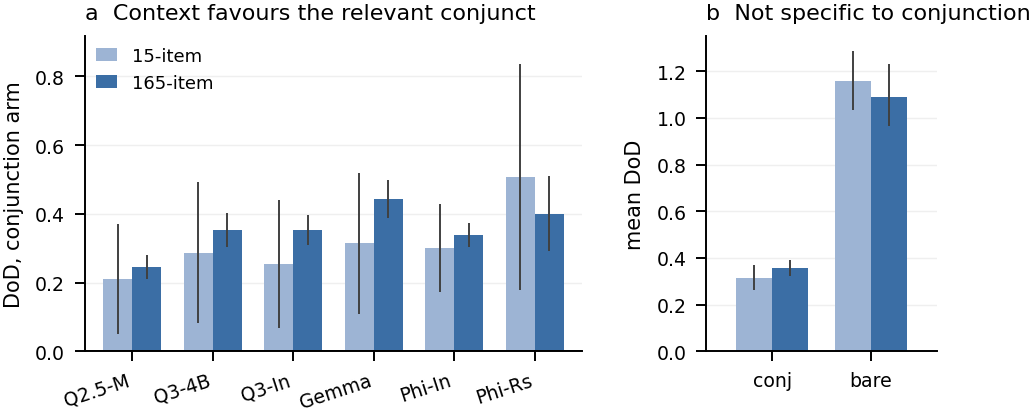

In [11]:
show_figure('fig1_behavior.png', 760)

## Reproduction table for this notebook

In [12]:
df = C.show(); C.save('01')

01_behavior_and_norms: ✅ 44 · ≈ 5 · ⚠ 3 · ❌ 2


id,section,analysis,reported,produced,status,note
A1,Results ¶1,"DoD R|N positive, 15 items",12/12,12/12,✅,
A1,Results ¶1,"DoD R|N Holm-significant, 15 items",12/12,12/12,✅,
A1,Results ¶1,"mean DoD R|N conj, 15 items",0.313,+0.3125,❌,"exact mean 0.31246, which rounds to 0.312; Results ¶1 prints 0.313 and Table tab:decomp prints 0.312"
A1,Results ¶1,"DoD R|N Holm-significant, 165 items",12/12,12/12,✅,
A1,Results ¶1,"mean DoD R|N conj, 165 items",0.356,+0.3560,✅,
A9,Discussion ¶1,banks agree to within 0.05 DoD (165 − 15),0.05,+0.050,✅,"|difference| = 0.044, within the stated 0.05"
A2,Results ¶1,"worst LOIO fold still p<.05, 15 items",12/12,12/12,✅,
A3,Results ¶1,"DoD R|I Holm-significant, 15 items",12/12,12/12,✅,
A3,Results ¶1,"DoD I|N Holm-significant, 15 items",0/12,0/12,✅,
A3,Results ¶1,"relevance share of full effect, 15 items",58–85,58–85,✅,


saved notebooks/_checks_01.csv
